In [1]:
%matplotlib inline
import hcipy as hci
import numpy as np
import matplotlib.pyplot as plt

In [2]:
grid = hci.make_uniform_grid([64,64], [2,1])

Text(0,0.5,'y')

/home/pinchen/anaconda2/envs/py3/lib/python3.5/site-packages/matplotlib/font_manager.py:1328: UserWarning: findfont: Font family ['sans-serif'] not found. Falling back to DejaVu Sans
  (prop.get_family(), self.defaultFamily[fontext]))


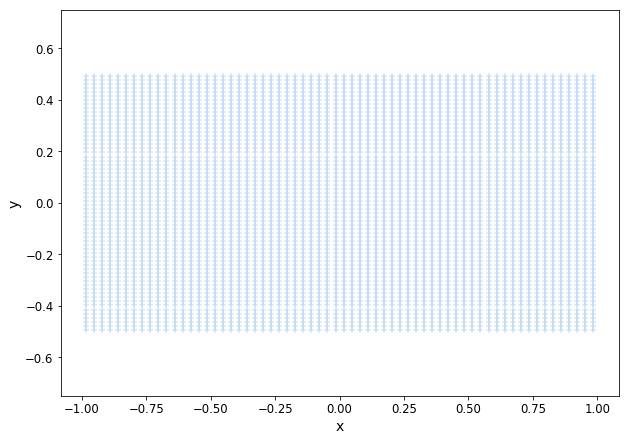

In [3]:
plt.plot(grid.x, grid.y, '+')
plt.axis('equal')
plt.xlabel('x')
plt.ylabel('y')


In [4]:
help(hci.make_uniform_grid)

Help on function make_uniform_grid in module hcipy.field.util:

make_uniform_grid(dims, extent, center=0, has_center=False)
    Create a uniformly-spaced :class:`Grid` of a certain shape and size.
    
    Parameters
    ----------
    dims : scalar or ndarray
            The number of points in each dimension. If this is a scalar, it will
            be multiplexed over all dimensions.
    extent : scalar or ndarray
            The total extent of the grid in each dimension.
    center : scalar or ndarray
            The center point. The grid will by symmetric around this point.
    has_center : boolean
            Does the grid has to have the center as one of its points. If this is
            False, this does not mean that the grid will not have the center.
    
    Returns
    -------
    Grid
            A :class:`Grid` with :class:`RegularCoords`.



In [5]:
print('Class of grid:  ', grid.coords.__class__)
print('Distance between points:  ', grid.delta)
print('Number of points on each dimension:  ', grid.dims)
print('Zero-point of the grid:', grid.zero)

Class of grid:   <class 'hcipy.field.coordinates.RegularCoords'>
Distance between points:   [0.03125  0.015625]
Number of points on each dimension:   [64 64]
Zero-point of the grid: [-0.984375  -0.4921875]


In [6]:
r = np.logspace(-1, 1, 11)
print(r)
print(np.log10(r))
theta = np.linspace(0, 2*np.pi, 11, endpoint=False)


[ 0.1         0.15848932  0.25118864  0.39810717  0.63095734  1.
  1.58489319  2.51188643  3.98107171  6.30957344 10.        ]
[-1.  -0.8 -0.6 -0.4 -0.2  0.   0.2  0.4  0.6  0.8  1. ]


In [7]:
coords = hci.SeparatedCoords((r, theta))
polar_grid = hci.PolarGrid(coords)
cart_grid = polar_grid.as_('cartesian')

/home/pinchen/anaconda2/envs/py3/lib/python3.5/site-packages/matplotlib/font_manager.py:1328: UserWarning: findfont: Font family ['sans-serif'] not found. Falling back to DejaVu Sans
  (prop.get_family(), self.defaultFamily[fontext]))


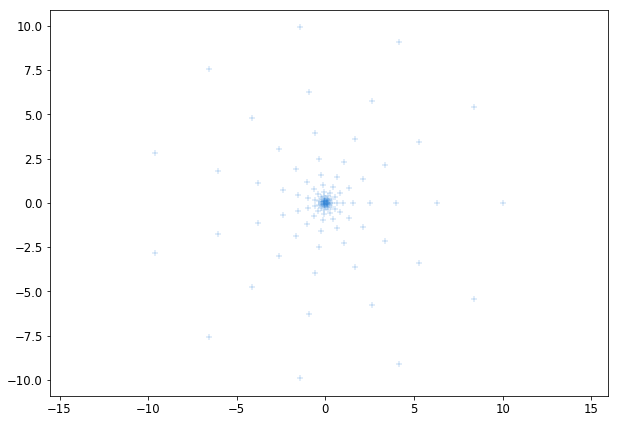

In [8]:
plt.plot(cart_grid.x, cart_grid.y, "+")
plt.axis('equal')
plt.show()

In [9]:
help(hci.SeparatedCoords)

Help on class SeparatedCoords in module hcipy.field.coordinates:

class SeparatedCoords(CoordsBase)
 |  A list of points that are separable along each dimension.
 |  
 |  The actual points are given by the iterated tensor product of the `separated_coords`.
 |  
 |  Parameters
 |  ----------
 |  separated_coords : list or tuple
 |          A tuple of a list of coordinates along each dimension.
 |  
 |  Attributes
 |  ----------
 |  separated_coords
 |          A tuple of a list of coordinates along each dimension.
 |  
 |  Method resolution order:
 |      SeparatedCoords
 |      CoordsBase
 |      builtins.object
 |  
 |  Methods defined here:
 |  
 |  __getitem__(self, i)
 |      The `i`-th point for these coordinates.
 |  
 |  __iadd__(self, b)
 |      Add `b` to the coordinates separately in-place.
 |  
 |  __imul__(self, f)
 |      Multiply each coordinate with `f` separately in-place.
 |  
 |  __init__(self, separated_coords)
 |      Initialize self.  See help(type(self)) for accur

In [10]:
try:
    print(polar_grid.x)
except AttributeError as err:
    print(err)

'PolarGrid' object has no attribute 'x'


In [11]:
values = np.exp(-(grid.x**2*10))*np.sin(20*grid.y)
field = hci.Field(values, grid)

/home/pinchen/anaconda2/envs/py3/lib/python3.5/site-packages/matplotlib/font_manager.py:1328: UserWarning: findfont: Font family ['sans-serif'] not found. Falling back to DejaVu Sans
  (prop.get_family(), self.defaultFamily[fontext]))


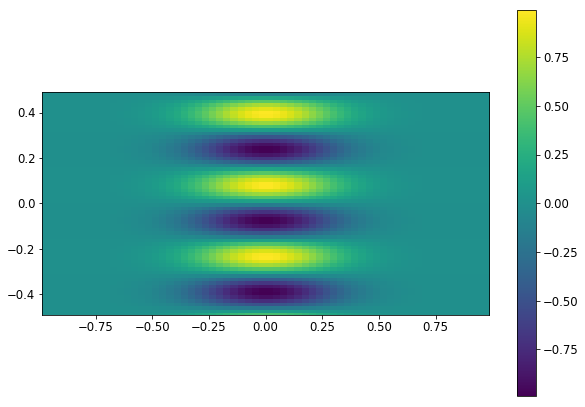

In [12]:
hci.imshow_field(field)
plt.colorbar()
plt.show()

In [13]:
values2 = np.exp(1j*grid.x*20)*np.sqrt(np.abs(np.sinc(5*grid.y)))
field2 = hci.Field(values2, grid)

/home/pinchen/anaconda2/envs/py3/lib/python3.5/site-packages/matplotlib/font_manager.py:1328: UserWarning: findfont: Font family ['sans-serif'] not found. Falling back to DejaVu Sans
  (prop.get_family(), self.defaultFamily[fontext]))


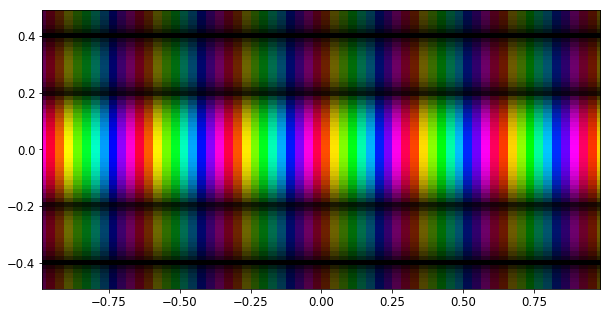

In [14]:
hci.imshow_field(field2)
plt.show()

In [15]:
mask = hci.circular_aperture(0.7)(grid)

/home/pinchen/anaconda2/envs/py3/lib/python3.5/site-packages/matplotlib/font_manager.py:1328: UserWarning: findfont: Font family ['sans-serif'] not found. Falling back to DejaVu Sans
  (prop.get_family(), self.defaultFamily[fontext]))


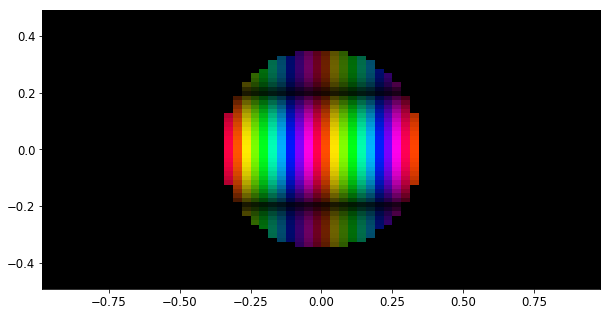

In [16]:
hci.imshow_field(field2, mask=mask)
plt.show()

/home/pinchen/anaconda2/envs/py3/lib/python3.5/site-packages/matplotlib/font_manager.py:1328: UserWarning: findfont: Font family ['sans-serif'] not found. Falling back to DejaVu Sans
  (prop.get_family(), self.defaultFamily[fontext]))


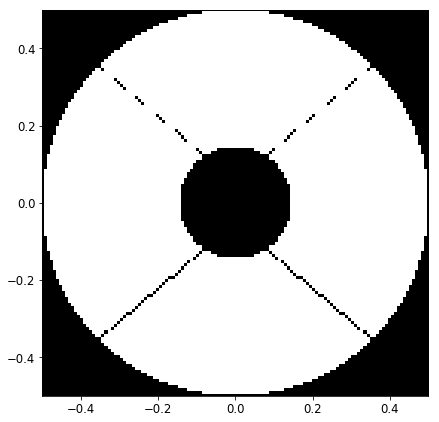

In [17]:
pupil_grid = hci.make_pupil_grid(128)
aperture = hci.make_magellan_aperture(True)

hci.imshow_field(aperture(pupil_grid), cmap='binary_r')
plt.show()

In [18]:
print(help(hci.make_pupil_grid))
print(help(hci.make_magellan_aperture))

Help on function make_pupil_grid in module hcipy.field.util:

make_pupil_grid(dims, diameter=1)
    Makes a new :class:`Grid`, meant for descretisation of a pupil-plane wavefront.
    
    This grid is symmetric around the origin, and therefore has no point exactly on
    the origin for an even number of pixels.
    
    Parameters
    ----------
    dims : ndarray or integer
            The number of pixels per dimension. If this is an integer, this number
            of pixels is used for all dimensions.
    diameter : ndarray or scalar
            The diameter of the grid in each dimension. If this is a scalar, this diameter
            is used for all dimensions.
    
    Returns
    -------
    Grid
            A :class:`CartesianGrid` with :class:`RegularCoords`.

None
Help on function make_magellan_aperture in module hcipy.aperture.realistic:

make_magellan_aperture(normalized=False)
    Make the Magellan aperture.
    
    Parameters
    ----------
    normalized : boolean
    

/home/pinchen/anaconda2/envs/py3/lib/python3.5/site-packages/matplotlib/font_manager.py:1328: UserWarning: findfont: Font family ['sans-serif'] not found. Falling back to DejaVu Sans
  (prop.get_family(), self.defaultFamily[fontext]))


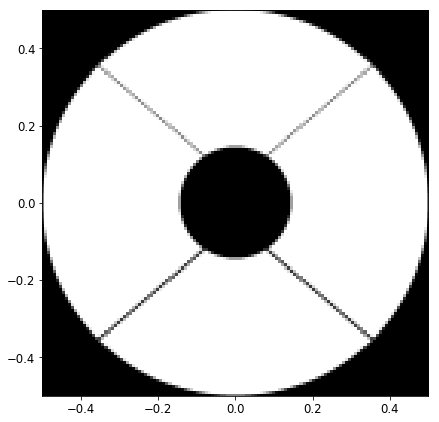

In [19]:
pupil = hci.evaluate_supersampled(aperture, pupil_grid, 8)
hci.imshow_field(pupil, cmap='gray')

In [20]:
pupil_grid = hci.make_pupil_grid(1024)
aperture = hci.circular_aperture(1)(pupil_grid)

In [21]:
wavefront = hci.Wavefront(aperture, 1)

In [22]:
focal_grid = hci.make_focal_grid(pupil_grid, 8, 16)

In [23]:
prop = hci.FraunhoferPropagator(pupil_grid, focal_grid)

In [24]:
img = prop.forward(wavefront)

/home/pinchen/anaconda2/envs/py3/lib/python3.5/site-packages/matplotlib/font_manager.py:1328: UserWarning: findfont: Font family ['sans-serif'] not found. Falling back to DejaVu Sans
  (prop.get_family(), self.defaultFamily[fontext]))


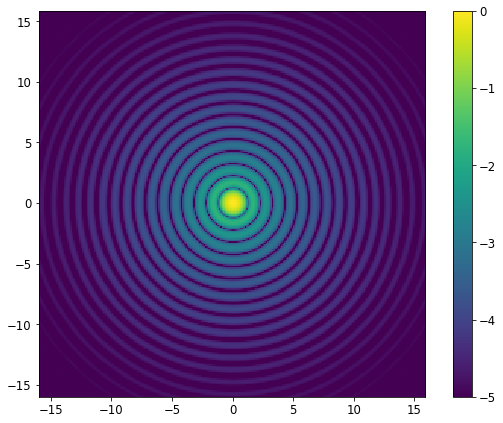

In [25]:
hci.imshow_field(np.log10(img.intensity/img.intensity.max()), vmin=-5)
plt.colorbar()

In [26]:
pupil_grid_2 = hci.make_pupil_grid(1024, 0.015)
aperture_2 = hci.circular_aperture(0.01)(pupil_grid_2)

In [27]:
fresnel_prop = hci.FresnelPropagator(pupil_grid_2, 2.0)

In [28]:
wf = hci.Wavefront(aperture_2, 500e-9)
img = fresnel_prop(wf)

/home/pinchen/anaconda2/envs/py3/lib/python3.5/site-packages/matplotlib/font_manager.py:1328: UserWarning: findfont: Font family ['sans-serif'] not found. Falling back to DejaVu Sans
  (prop.get_family(), self.defaultFamily[fontext]))


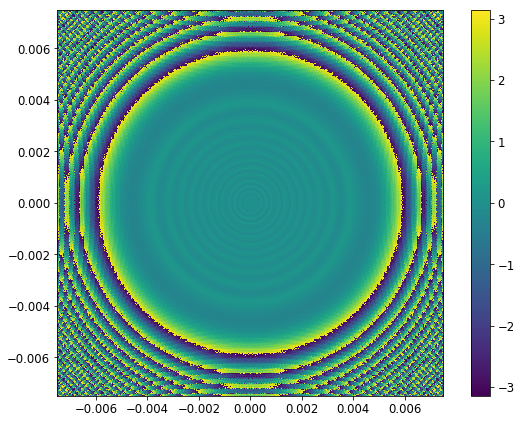

In [29]:
hci.imshow_field(img.phase)
plt.colorbar()
plt.show()

/home/pinchen/anaconda2/envs/py3/lib/python3.5/site-packages/matplotlib/font_manager.py:1328: UserWarning: findfont: Font family ['sans-serif'] not found. Falling back to DejaVu Sans
  (prop.get_family(), self.defaultFamily[fontext]))


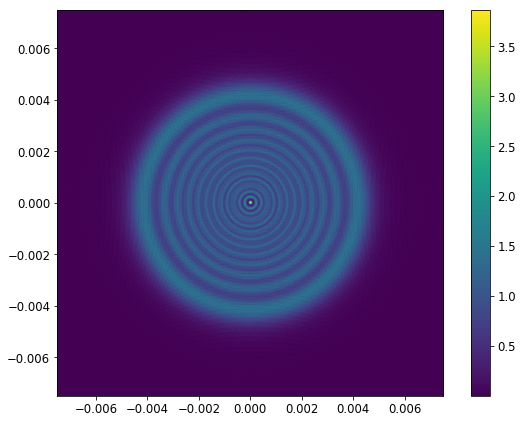

In [30]:
hci.imshow_field(img.intensity)
plt.colorbar()
plt.show()

In [31]:
aberration = hci.SurfaceAberration(pupil_grid, 1/4, 1)

In [32]:
wf = hci.Wavefront(aperture)
img = prop(aberration(wf))

In [33]:
help(hci.SurfaceAberration)

Help on class SurfaceAberration in module hcipy.optics.aberration:

class SurfaceAberration(hcipy.optics.optical_element.PolychromaticOpticalElement)
 |  Method resolution order:
 |      SurfaceAberration
 |      hcipy.optics.optical_element.PolychromaticOpticalElement
 |      hcipy.optics.optical_element.OpticalElement
 |      builtins.object
 |  
 |  Methods defined here:
 |  
 |  __init__(self, pupil_grid, ptv, diameter, exponent=-2.5, refractive_index=-1, aperture=None, remove_modes=None)
 |      Initialize self.  See help(type(self)) for accurate signature.
 |  
 |  ----------------------------------------------------------------------
 |  Methods inherited from hcipy.optics.optical_element.PolychromaticOpticalElement:
 |  
 |  backward(self, wavefront)
 |  
 |  forward(self, wavefront)
 |  
 |  get_instance(self, input_grid, wavelength)
 |  
 |  get_transformation_matrix_backward(self, input_grid, wavelength)
 |  
 |  get_transformation_matrix_forward(self, input_grid, wavelength

/home/pinchen/anaconda2/envs/py3/lib/python3.5/site-packages/matplotlib/font_manager.py:1328: UserWarning: findfont: Font family ['sans-serif'] not found. Falling back to DejaVu Sans
  (prop.get_family(), self.defaultFamily[fontext]))


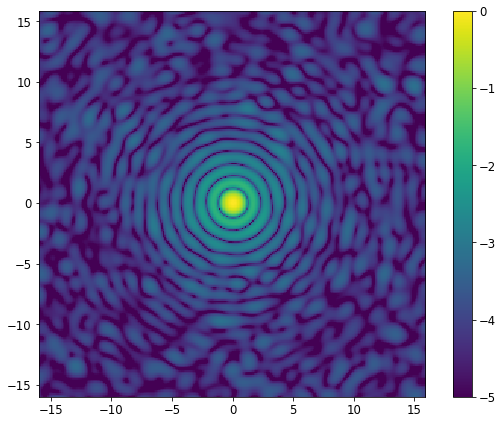

In [34]:
hci.imshow_field(np.log10(img.intensity/img.intensity.max()), vmin=-5)
plt.colorbar()